Device: cpu | run: v4_order_speed_aug_sync
split       train  val  test
severity_g                  
0.0            30   10     9
6.0            30   10     9
10.0           30    9     9
15.0           30    9     9
20.0           30   10     9
25.0           29    9     9
30.0           29    9     9
35.0           27    9     9
  50/382 files
  100/382 files
  150/382 files
  200/382 files
  250/382 files
  300/382 files
  350/382 files
train: vib (2115, 6, 5000)  mic (2115, 1, 25000)
val  : vib (675, 6, 5000)  mic (675, 1, 25000)
test : vib (648, 6, 5000)  mic (648, 1, 25000)
Done in 49 s
File-name speed / tach speed: median 1.0236, range 1.0168-1.0297  (a constant ~1.025 means the file names assume 51.2 kHz)
Baseline vib + speed       acc 0.793
Baseline mic + speed       acc 0.319
Baseline vib+mic + speed   acc 0.807
Sync features: (36,) | side input per model: {'early': 36, 'A': 31, 'B': 6}
Baseline sync vib (logistic)   acc 0.844
Baseline sync vib (boosting)   acc 0.847
Early-fu

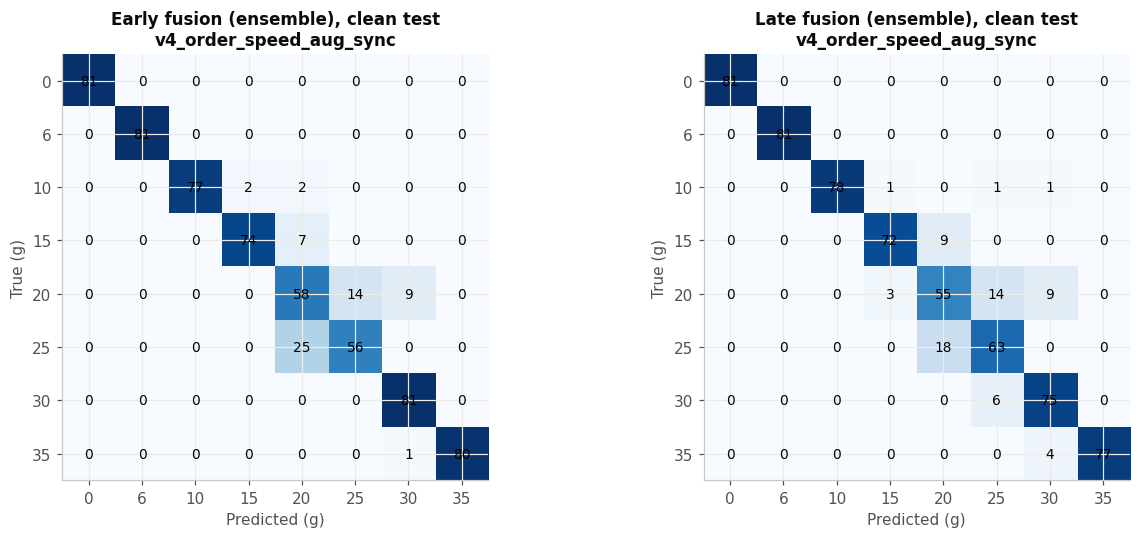

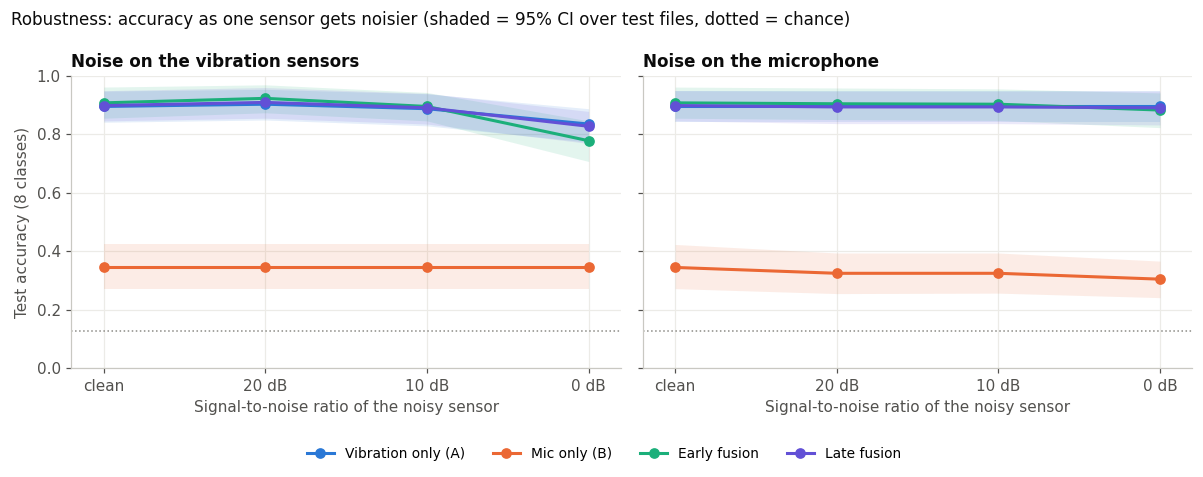

saved fig1_robustness_vs_snr.png


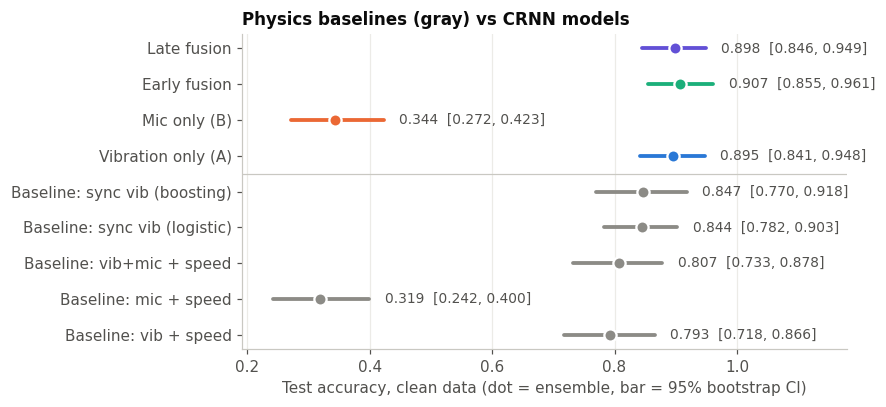

saved fig2_accuracy_with_ci.png


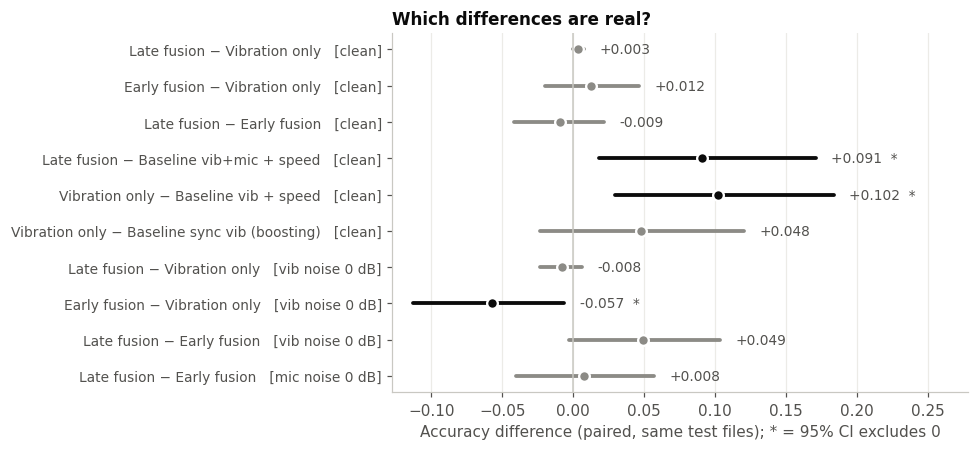

saved fig3_paired_differences.png


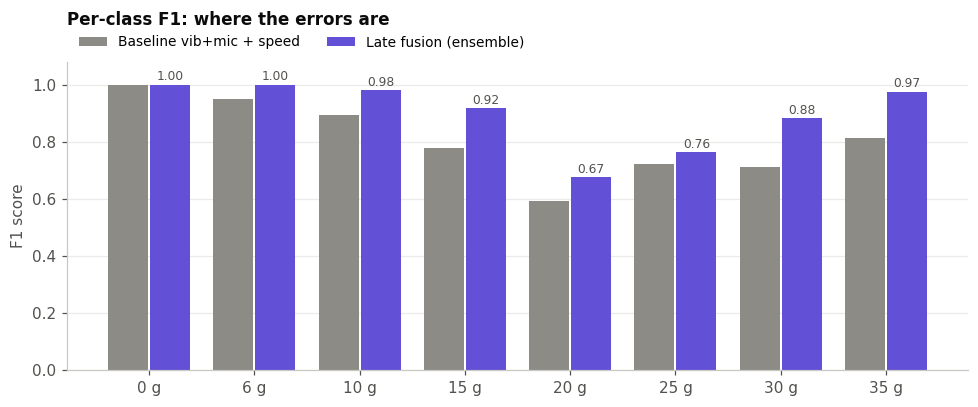

saved fig4_per_class_f1.png


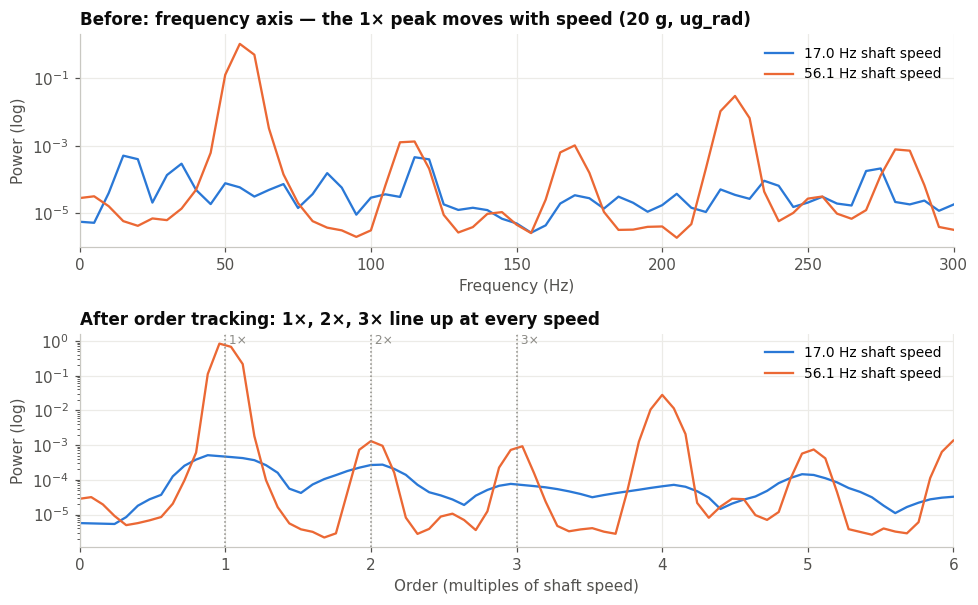

saved fig5_order_tracking.png


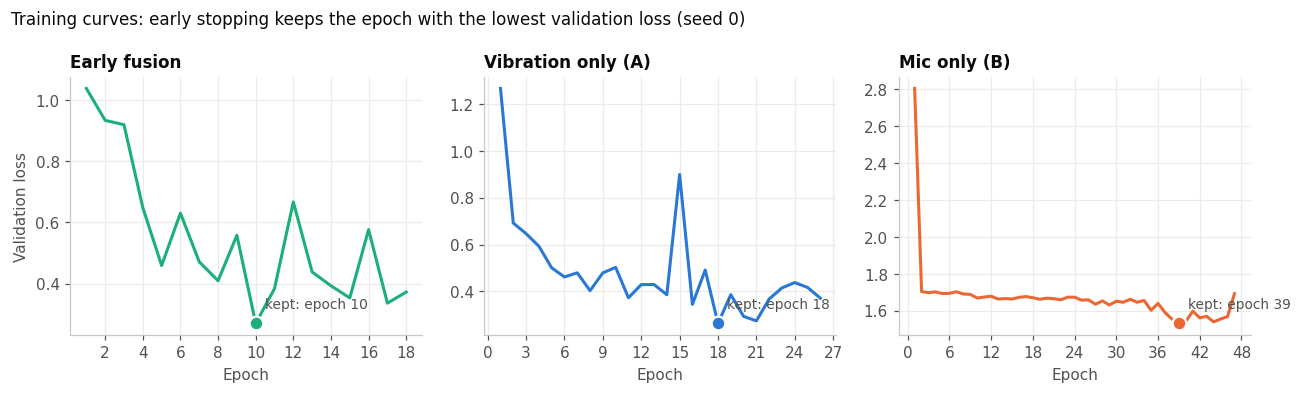

saved fig6_training_curves.png


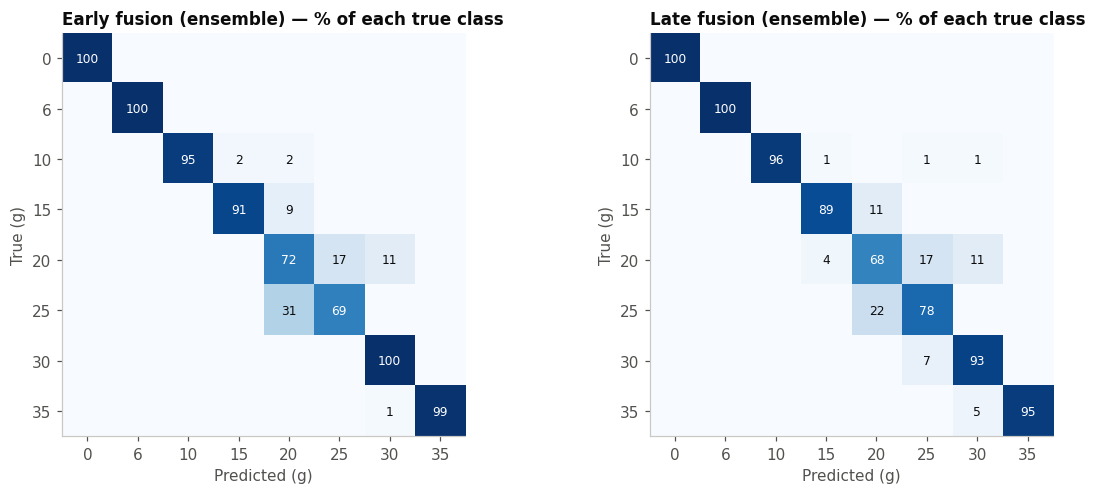

saved fig7_confusion_percent.png

[v4_order_speed_aug_sync] Deployment (one model; the 3-seed ensemble is 3x): batch of 1, this CPU (model only; STFT and sync features add a few ms)
              model  parameters  size_float32_KB  size_int8_KB (est.)  CPU_ms_per_window
 Vibration only (A)      203416              795                  199               4.77
       Mic only (B)      202296              790                  198              12.51
       Early fusion      203640              795                  199               4.49
Late fusion (A + B)      405712             1585                  397              17.28

All README figures saved in: C:\Users\shaghaye\Desktop\sideproject\project2\mafaulda_npy\figures_v4_order_speed_aug_sync


In [ ]:

import os
import time
import numpy as np
import pandas as pd
from scipy import signal
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Folder with the .npy files and manifest_split.csv made by download_mafaulda.py
FOLDER = "mafaulda_npy"

USE_ORDER = True            
USE_SPEED = True             
AUGMENT = True              
USE_SYNC = True              

FS_IN = 50_000

DECIM_V, FS_V, WIN_V = 10, 5_000, 5_000
NPERSEG_V, NOVERLAP_V, FMAX_V = 1000, 750, 1000
ORDERS = np.arange(200) * 0.08       
# Mic: 25 kHz
DECIM_M, FS_M, WIN_M = 2, 25_000, 25_000
NPERSEG_M50, NOVERLAP_M50, POOL_M = 5000, 3750, 10   
NPERSEG_M20, NOVERLAP_M20 = 1250, 625                
FMAX_M = 10_000
N_FREQ = 200

AUG_P = 0.25                
AUG_SNR = (0, 30)            
SEEDS = [0, 1, 2]
EPOCHS, PATIENCE, BATCH, LR, WEIGHT_DECAY = 50, 8, 32, 1e-3, 1e-4
SNR_LEVELS = [20, 10, 0]
N_BOOT = 2000
HARM = [1, 2, 3]            
EPS = 1e-10

VIB, MIC = [0, 1, 2, 3, 4, 5], [6]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TAG = (f"v4_{'order' if USE_ORDER else 'hz'}_{'speed' if USE_SPEED else 'nospeed'}"
       f"_{'aug' if AUGMENT else 'noaug'}_{'sync' if USE_SYNC else 'nosync'}")
print("Device:", DEVICE, "| run:", TAG)



m = pd.read_csv(os.path.join(FOLDER, "manifest_split.csv"))
classes = np.sort(m["severity_g"].unique())
m["label"] = m["severity_g"].map({g: i for i, g in enumerate(classes)})
print(pd.crosstab(m["severity_g"], m["split"])[["train", "val", "test"]])



def prep(x, decim):
    x = signal.detrend(x.astype(np.float64), axis=0, type="linear")
    x = signal.decimate(x, decim, ftype="fir", zero_phase=True, axis=0)
    return x.astype(np.float32)


def windows(x, win):
    return np.stack([x[s:s + win].T for s in range(0, x.shape[0] - win + 1, win // 2)])


def tach_revolutions(tach):
    """G1/G2: fit revolutions(n) = a*n + b (n = raw sample index) from the once-per-rev pulses."""
    lo, hi = np.percentile(tach, [1, 99])
    high = tach > (lo + hi) / 2
    on = high if high.mean() < 0.5 else ~high          
    starts = np.flatnonzero(~on[:-1] & on[1:]) + 1      
    a, b = np.polyfit(starts, np.arange(len(starts)), 1)
    return a, b


t0 = time.time()
SETS = ["train", "val", "test"]
rv, rm, lab, spd, fid, ta, tb, t0w, spd_name = ({s: [] for s in SETS} for _ in range(9))
for k, row in enumerate(m.itertuples(), 1):
    x = np.load(os.path.join(FOLDER, row.file))
    a_t, b_t = tach_revolutions(x[:, 0].astype(np.float64))
    wv, wm = windows(prep(x[:, 1:7], DECIM_V), WIN_V), windows(prep(x[:, 7:8], DECIM_M), WIN_M)
    nw = len(wv)
    rv[row.split].append(wv)
    rm[row.split].append(wm)
    lab[row.split] += [row.label] * nw
    spd[row.split] += [a_t * FS_IN] * nw                 
    spd_name[row.split] += [row.speed_hz] * nw           
    ta[row.split] += [a_t] * nw                          
    tb[row.split] += [b_t] * nw
    t0w[row.split] += [i * FS_IN // 2 for i in range(nw)]   
    fid[row.split] += [k] * nw                           
    if k % 50 == 0:
        print(f"  {k}/{len(m)} files")
for s in SETS:
    rv[s], rm[s] = np.concatenate(rv[s]), np.concatenate(rm[s])
    lab[s], fid[s] = np.array(lab[s]), np.array(fid[s])
    spd[s] = np.array(spd[s], dtype=np.float32)
    spd_name[s] = np.array(spd_name[s], dtype=np.float32)
    ta[s], tb[s], t0w[s] = np.array(ta[s]), np.array(tb[s]), np.array(t0w[s], dtype=np.float64)
    print(f"{s:5s}: vib {rv[s].shape}  mic {rm[s].shape}")
print(f"Done in {time.time() - t0:.0f} s")
ratio = np.concatenate([spd_name[s] / spd[s] for s in SETS])
print(f"File-name speed / tach speed: median {np.median(ratio):.4f}, range {ratio.min():.4f}-{ratio.max():.4f}"
      "  (a constant ~1.025 means the file names assume 51.2 kHz)")


def one_x(w, speed, fs):
    spec = np.abs(np.fft.rfft(w * np.hanning(w.shape[-1]), axis=-1))
    freqs = np.fft.rfftfreq(w.shape[-1], 1 / fs)
    out = np.zeros(w.shape[:2])
    for i in range(len(w)):
        band = (freqs > speed[i] - 2) & (freqs < speed[i] + 2)
        out[i] = np.log(spec[i][:, band].max(axis=1) / speed[i] ** 2 + 1e-12)
    return out


Fb = {s: np.hstack([one_x(rv[s], spd[s], FS_V), one_x(rm[s], spd[s], FS_M),
                    np.log(spd[s])[:, None]]) for s in SETS}
base_pred = {}
for name, cols in [("Baseline vib + speed", VIB + [7]), ("Baseline mic + speed", MIC + [7]),
                   ("Baseline vib+mic + speed", VIB + MIC + [7])]:
    sc = StandardScaler().fit(Fb["train"][:, cols])
    clf = LogisticRegression(max_iter=3000).fit(sc.transform(Fb["train"][:, cols]), lab["train"])
    base_pred[name] = clf.predict(sc.transform(Fb["test"][:, cols]))
    print(f"{name:26s} acc {accuracy_score(lab['test'], base_pred[name]):.3f}")


def power_spec(w, nfft, hop, nbins, pool=1, chunk=256):
    """w: (n, C, L) tensor -> (n, C, nbins // pool, frames) power. Same scaling as scipy.signal.stft."""
    win = torch.hann_window(nfft)
    out = []
    for i in range(0, len(w), chunk):
        x = w[i:i + chunk]
        n, C, L = x.shape
        Zc = torch.stft(x.reshape(n * C, L), n_fft=nfft, hop_length=hop, window=win,
                        center=False, return_complex=True) / win.sum()
        P = Zc[:, :nbins].abs() ** 2
        out.append(P.reshape(n, C, nbins // pool, pool, -1).mean(3))
    return torch.cat(out)


def power_vib(wv):                                 
    return power_spec(wv, NPERSEG_V, NPERSEG_V - NOVERLAP_V, N_FREQ)


def power_mic50(wm):                                
    return power_spec(wm, NPERSEG_M50, NPERSEG_M50 - NOVERLAP_M50, N_FREQ * POOL_M, pool=POOL_M)


def power_mic20(wm):                                 
    return power_spec(wm, NPERSEG_M20, NPERSEG_M20 - NOVERLAP_M20, FMAX_M * NPERSEG_M20 // FS_M)


def order_index(speed):
    """Interpolation positions that map the 5 Hz grid onto the order grid (per window).
    Note: this is spectral order normalization by interpolation. Its order resolution is
    5 Hz / speed, i.e. ~0.4x at 12 Hz but ~0.08x at 62 Hz, so low speeds stay blurry."""
    pos = ORDERS[None, :] * speed[:, None] / (FS_V / NPERSEG_V)
    i0 = np.clip(np.floor(pos).astype(np.int64), 0, N_FREQ - 2)
    return torch.from_numpy(i0), torch.from_numpy(np.clip(pos - i0, 0, 1).astype(np.float32))


T = lambda a: torch.from_numpy(a)
RV = {s: T(rv[s]) for s in SETS}                    
RM = {s: T(rm[s]) for s in SETS}
TA = {s: T(ta[s]) for s in SETS}
TB = {s: T(tb[s]) for s in SETS}
T0W = {s: T(t0w[s]) for s in SETS}



def sync_vectors(w, decim, a, b, start):
    """Complex amplitude of the k-th shaft harmonic for every channel.
    w: (B, C, L) window at the decimated rate; a, b: tach fit; start: raw start sample. -> {k: (B, C)}"""
    L = w.shape[-1]
    j = torch.arange(L, dtype=torch.float64)
    rev = a[:, None] * (start[:, None] + j[None, :] * decim) + b[:, None]
    theta = 2 * np.pi * (rev - torch.floor(rev))                     # shaft angle, 0 = tach pulse
    win = torch.hann_window(L, periodic=False, dtype=torch.float64)
    wc = (w.to(torch.float64) * win).to(torch.complex128)
    return {k: (2 * (wc * torch.exp(-1j * k * theta)[:, None, :]).sum(-1) / win.sum()).to(torch.complex64)
            for k in HARM}


def sync_features(wv, wm, a, b, start):
    """(B, 36): vib [log|Xk|/speed^2 for k=1..3, cos/sin of 1x phase] x 6 ch, mic same (5), log speed."""
    f = a * FS_IN                                                   
    s2 = (f ** 2)[:, None].float()
    Vv, Vm = sync_vectors(wv, DECIM_V, a, b, start), sync_vectors(wm, DECIM_M, a, b, start)
    vib = [torch.log(Vv[k].abs() / s2 + 1e-12) for k in HARM] + [torch.cos(Vv[1].angle()), torch.sin(Vv[1].angle())]
    mic = [torch.log(Vm[k].abs() / s2 + 1e-12) for k in HARM] + [torch.cos(Vm[1].angle()), torch.sin(Vm[1].angle())]
    return torch.cat(vib + mic + [torch.log(f)[:, None].float()], dim=1)



SYNC_VIB, SYNC_MIC, SYNC_SPEED = list(range(30)), list(range(30, 35)), [35]


def aux_cols(kind):
    """Side-input columns each model may see (the mic model must not see vibration features)."""
    cols = []
    if USE_SYNC:
        cols += {"early": SYNC_VIB + SYNC_MIC, "A": SYNC_VIB, "B": SYNC_MIC}[kind]
    if USE_SPEED:
        cols += SYNC_SPEED
    return cols


def chunked_sync(wv, wm, a, b, start, chunk=128):
    return torch.cat([sync_features(wv[i:i + chunk], wm[i:i + chunk], a[i:i + chunk], b[i:i + chunk],
                                    start[i:i + chunk]) for i in range(0, len(wv), chunk)])


AUX_RAW = {s: chunked_sync(RV[s], RM[s], TA[s], TB[s], T0W[s]) for s in SETS}   # clean, (n, 36)
AUX_MEAN, AUX_STD = AUX_RAW["train"].mean(0), AUX_RAW["train"].std(0) + 1e-6
AUX = {s: (AUX_RAW[s] - AUX_MEAN) / AUX_STD for s in SETS}
print("Sync features:", tuple(AUX["train"].shape[1:]),
      "| side input per model:", {k: len(aux_cols(k)) for k in ("early", "A", "B")})


_bc = SYNC_VIB + SYNC_SPEED
for name, clf in [("Baseline sync vib (logistic)", make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))),
                  ("Baseline sync vib (boosting)", HistGradientBoostingClassifier(random_state=0))]:
    clf.fit(AUX_RAW["train"][:, _bc].numpy(), lab["train"])
    base_pred[name] = clf.predict(AUX_RAW["test"][:, _bc].numpy())
    print(f"{name:30s} acc {accuracy_score(lab['test'], base_pred[name]):.3f}")
OI, OW = {}, {}
for s in SETS:
    OI[s], OW[s] = order_index(spd[s])
raw_test_v, raw_test_m = rv["test"], rm["test"]     
del rv, rm



def to_order(P, i0, w, force=False):
    """P: (B, C, 200, T) on the Hz grid -> (B, C, 200, T) on the order grid (linear interp)."""
    if not (USE_ORDER or force):
        return P
    B, C, _, Tn = P.shape
    i0 = i0[:, None, :, None].expand(B, C, N_FREQ, Tn)
    w = w[:, None, :, None]
    return torch.gather(P, 2, i0) * (1 - w) + torch.gather(P, 2, i0 + 1) * w


def log_vib(wv, i0, w):
    return torch.log(to_order(power_vib(wv), i0, w) + EPS)       


def log_mic50(wm):
    return torch.log(power_mic50(wm) + EPS)                      


def log_mic20(wm):
    return torch.log(power_mic20(wm) + EPS)                       



def chunked(fn, *arrays, chunk=256):
    return torch.cat([fn(*[a[i:i + chunk] for a in arrays]) for i in range(0, len(arrays[0]), chunk)])


_v = chunked(log_vib, RV["train"], OI["train"], OW["train"])
_m50 = chunked(log_mic50, RM["train"])
_m20 = chunked(log_mic20, RM["train"])
MEAN = torch.cat([_v, _m50], 1).mean(dim=(0, 2, 3), keepdim=True)
STD = torch.cat([_v, _m50], 1).std(dim=(0, 2, 3), keepdim=True)
MEAN20, STD20 = _m20.mean(), _m20.std()
del _v, _m50, _m20


def model_inputs(kind, wv, wm, i0, w):
    """Standardized inputs for one model type. kind: 'early' (7 ch), 'A' (vib, 6 ch), 'B' (mic, 20 Hz)."""
    if kind == "B":
        return (log_mic20(wm) - MEAN20) / STD20
    vib = (log_vib(wv, i0, w) - MEAN[:, :6]) / STD[:, :6]
    if kind == "A":
        return vib
    return torch.cat([vib, (log_mic50(wm) - MEAN[:, 6:]) / STD[:, 6:]], dim=1)


def features(wv, wm, i0, w):
    """Eval features for all model types: {'early': (n,7,200,17), 'B': (n,1,500,39)}."""
    return {"early": chunked(lambda a, b, c, d: model_inputs("early", a, b, c, d), wv, wm, i0, w),
            "B": chunked(lambda b: model_inputs("B", None, b, None, None), wm)}


FEAT = {s: features(RV[s], RM[s], OI[s], OW[s]) for s in ["val", "test"]}
for s in ["val", "test"]:
    FEAT[s]["aux"] = AUX[s]
del RV["val"], RM["val"], RV["test"], RM["test"]
print("Early-fusion input:", tuple(FEAT["val"]["early"].shape[1:]),
      "| late-fusion mic input:", tuple(FEAT["val"]["B"].shape[1:]))

TR = dict(V=RV["train"], M=RM["train"], OI=OI["train"], OW=OW["train"], y=T(lab["train"]).long(),
          A=TA["train"], B=TB["train"], S0=T0W["train"])



def add_noise_t(x, snr_db, gen):
    """x: (B, C, L); white noise at snr_db (B,) per window and channel, relative to that channel's power."""
    p_sig = x.pow(2).mean(-1, keepdim=True)
    sigma = torch.sqrt(p_sig / 10 ** (snr_db[:, None, None] / 10))
    return x + torch.randn(x.shape, generator=gen) * sigma


def train_batch(kind, idx, gen):
    B = len(idx)
    wv, wm = TR["V"][idx], TR["M"][idx]
    if AUGMENT:
        mode = torch.rand(B, generator=gen)                    
        snr = AUG_SNR[0] + (AUG_SNR[1] - AUG_SNR[0]) * torch.rand(B, generator=gen)
        vib_m, mic_m = mode < AUG_P, (mode >= AUG_P) & (mode < 2 * AUG_P)
        if kind != "B" and vib_m.any():
            wv = wv.clone()
            wv[vib_m] = add_noise_t(wv[vib_m], snr[vib_m], gen)
        if kind != "A" and mic_m.any():
            wm = wm.clone()
            wm[mic_m] = add_noise_t(wm[mic_m], snr[mic_m], gen)
    x = model_inputs(kind, wv, wm, TR["OI"][idx], TR["OW"][idx])
    aux = (sync_features(wv, wm, TR["A"][idx], TR["B"][idx], TR["S0"][idx]) - AUX_MEAN) / AUX_STD
    return x, aux[:, aux_cols(kind)]                  # sync features recomputed from the noisy batch



class CRNN(nn.Module):
    """CNN on the spectrogram + GRU over time. The side input (speed and/or sync features) is encoded
    to 16 numbers and joined to every GRU time step and to the final layers."""
    def __init__(self, in_ch, n_aux, n_classes=8):
        super().__init__()
        self.n_aux = n_aux
        k = 16 if n_aux else 0
        self.aux_enc = nn.Sequential(nn.Linear(n_aux, 16), nn.ReLU()) if n_aux else None

        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
                                 nn.ReLU(), nn.MaxPool2d((2, 1)))

        self.cnn = nn.Sequential(block(in_ch, 16), block(16, 32), block(32, 64), block(64, 64),
                                 nn.AdaptiveMaxPool2d((12, None)))   # 200 bins: no-op; 500: -> 12
        self.proj = nn.Linear(64 * 12, 128)
        self.gru = nn.GRU(128 + k, 64, batch_first=True)
        self.head = nn.Sequential(nn.Linear(64 + k, 32), nn.ReLU(), nn.Dropout(0.3),
                                  nn.Linear(32, n_classes))

    def forward(self, x, aux):
        x = self.proj(self.cnn(x).permute(0, 3, 1, 2).flatten(2))
        if self.n_aux:
            e = self.aux_enc(aux)
            x = torch.cat([x, e[:, None, :].expand(-1, x.shape[1], -1)], dim=2)
        _, h = self.gru(x)
        h = torch.cat([h[-1], e], dim=1) if self.n_aux else h[-1]
        return self.head(h)


N_CH = {"early": 7, "A": 6, "B": 1}


def new_model(kind):
    return CRNN(N_CH[kind], len(aux_cols(kind)))


@torch.no_grad()
def predict_proba(model, inputs):
    X, aux = inputs
    model.eval()
    out = []
    for i in range(0, len(X), 256):
        xb, ab = X[i:i + 256].to(DEVICE), aux[i:i + 256].to(DEVICE)
        out.append(torch.softmax(model(xb, ab), dim=1).cpu().numpy())
    return np.concatenate(out)


def eval_inputs(kind, feat):
    x = {"early": feat["early"], "A": feat["early"][:, VIB], "B": feat["B"]}[kind]
    return x, feat["aux"][:, aux_cols(kind)]


def train_model(kind, seed):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = new_model(kind).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    va_in, yva, n = eval_inputs(kind, FEAT["val"]), lab["val"], len(TR["y"])
    best, best_state, wait, best_epoch = np.inf, None, 0, 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for idx in torch.randperm(n, generator=gen).split(BATCH):
            xb, ab = train_batch(kind, idx, gen)
            opt.zero_grad()
            loss = nn.functional.cross_entropy(model(xb.to(DEVICE), ab.to(DEVICE)), TR["y"][idx].to(DEVICE))
            loss.backward()
            opt.step()
        p = predict_proba(model, va_in)
        va_loss = -np.log(p[np.arange(len(yva)), yva] + 1e-12).mean()
        HIST.setdefault((kind, seed), []).append((epoch, va_loss, (p.argmax(1) == yva).mean()))
        if va_loss < best:
            best, wait, best_epoch = va_loss, 0, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        if epoch % 5 == 0 or wait == 0:
            print(f"    epoch {epoch:2d}  val loss {va_loss:.3f}  val acc {(p.argmax(1) == yva).mean():.3f}")
        if wait >= PATIENCE:
            break
    model.load_state_dict(best_state)
    BEST_EPOCH[(kind, seed)] = best_epoch
    return model


HIST, BEST_EPOCH = {}, {}   



idx = torch.from_numpy(np.random.default_rng(0).choice(len(TR["y"]), 20, replace=False))
Xp, Sp = train_batch("early", idx, torch.Generator().manual_seed(0))
Xp, Sp, yp = Xp.to(DEVICE), Sp.to(DEVICE), TR["y"][idx].to(DEVICE)
pilot = new_model("early").to(DEVICE)
opt = torch.optim.Adam(pilot.parameters(), lr=LR)
for _ in range(200):
    pilot.train()
    opt.zero_grad()
    nn.functional.cross_entropy(pilot(Xp, Sp), yp).backward()
    opt.step()
pilot.eval()
pilot_acc = (pilot(Xp, Sp).argmax(1) == yp).float().mean().item()
print(f"Pilot: train accuracy on 20 windows = {pilot_acc:.2f}  (should be ~1.00)")
assert pilot_acc > 0.9, "Model cannot memorize 20 windows -> bug in model or data"


models = {}
for seed in SEEDS:
    print(f"\n=== Seed {seed} ===")
    mdl = {}
    for kind, label in [("early", "Run 1: early fusion (7 channels)"), ("A", "Run 2: model A (vibration)"),
                        ("B", "Run 2: model B (mic, 20 Hz bins)")]:
        print("  " + label)
        mdl[kind] = train_model(kind, seed)
        torch.save(mdl[kind].state_dict(), os.path.join(FOLDER, f"{TAG}_{kind}_seed{seed}.pt"))
    pA = predict_proba(mdl["A"], eval_inputs("A", FEAT["val"]))
    pB = predict_proba(mdl["B"], eval_inputs("B", FEAT["val"]))
    ws = np.linspace(0, 1, 11)
    mdl["w"] = ws[int(np.argmax([((w * pA + (1 - w) * pB).argmax(1) == lab["val"]).mean() for w in ws]))]
    print(f"  Late-fusion weight on vibration (from val): {mdl['w']:.1f}")
    models[seed] = mdl


def add_noise(w, snr_db, rng):
    p_sig = (w ** 2).mean(axis=-1, keepdims=True)
    return w + rng.standard_normal(w.shape).astype(np.float32) * np.sqrt(p_sig / 10 ** (snr_db / 10))


def test_features(cond):
    if cond == "clean":
        return FEAT["test"]
    sensor, snr = cond
    rng = np.random.default_rng(123)
    wv = add_noise(raw_test_v, snr, rng) if sensor == "vib" else raw_test_v
    wm = add_noise(raw_test_m, snr, rng) if sensor == "mic" else raw_test_m
    feat = features(T(wv), T(wm), OI["test"], OW["test"])
    feat["aux"] = (chunked_sync(T(wv), T(wm), TA["test"], TB["test"], T0W["test"]) - AUX_MEAN) / AUX_STD
    return feat


def predict_all(feat):
    """Probabilities per seed and for the ensemble (average over seeds)."""
    out = {}
    for seed, md in models.items():
        pE = predict_proba(md["early"], eval_inputs("early", feat))
        pA = predict_proba(md["A"], eval_inputs("A", feat))
        pB = predict_proba(md["B"], eval_inputs("B", feat))
        out[seed] = {"Vibration only (A)": pA, "Mic only (B)": pB, "Early fusion": pE,
                     "Late fusion": md["w"] * pA + (1 - md["w"]) * pB}
    out["ensemble"] = {k: np.mean([out[s][k] for s in models], axis=0) for k in out[SEEDS[0]]}
    return out


conditions = ["clean"] + [("mic", s) for s in SNR_LEVELS] + [("vib", s) for s in SNR_LEVELS]
cname = lambda c: c if c == "clean" else f"{c[0]} noise {c[1]} dB"
MODEL_ORDER = ["Vibration only (A)", "Mic only (B)", "Early fusion", "Late fusion"]
rows, ens_pred, ens_prob = [], {}, {}
for cond in conditions:
    probs = predict_all(test_features(cond))
    ens_prob[cname(cond)] = probs["ensemble"]
    ens_pred[cname(cond)] = {k: p.argmax(1) for k, p in probs["ensemble"].items()}
    for seed, d in probs.items():
        for name, p in d.items():
            pred = p.argmax(1)
            rows.append({"condition": cname(cond), "model": name, "seed": seed,
                         "acc": accuracy_score(lab["test"], pred),
                         "f1": f1_score(lab["test"], pred, average="macro")})
    print("tested:", cname(cond))
res = pd.DataFrame(rows)
res.to_csv(os.path.join(FOLDER, f"results_all_runs_{TAG}.csv"), index=False)



files = np.unique(fid["test"])
rng_b = np.random.default_rng(0)

file_cls = np.array([lab["test"][fid["test"] == f][0] for f in files])
BOOT = np.hstack([rng_b.choice(np.where(file_cls == c)[0], size=(N_BOOT, int((file_cls == c).sum())))
                  for c in np.unique(file_cls)])
n_win = np.array([(fid["test"] == f).sum() for f in files])


def per_file_correct(pred):
    return np.array([(pred[fid["test"] == f] == lab["test"][fid["test"] == f]).sum() for f in files])


def boot_acc(pred):
    c = per_file_correct(pred)
    return c[BOOT].sum(1) / n_win[BOOT].sum(1)


def ci(a):
    return np.percentile(a, [2.5, 97.5])



seed_rows = res[res["seed"] != "ensemble"]
summ = seed_rows.groupby(["model", "condition"])["acc"].agg(["mean", "std"])
summ["v"] = summ["mean"].map("{:.3f}".format) + " ± " + summ["std"].map("{:.3f}".format)
table1 = summ["v"].unstack("condition").loc[MODEL_ORDER, [cname(c) for c in conditions]]


table2 = pd.DataFrame(index=MODEL_ORDER + list(base_pred), columns=[cname(c) for c in conditions])
for c, d in ens_pred.items():
    for k, pred in d.items():
        lo, hi = ci(boot_acc(pred))
        table2.loc[k, c] = f"{accuracy_score(lab['test'], pred):.3f} [{lo:.3f}, {hi:.3f}]"
for k, pred in base_pred.items():
    lo, hi = ci(boot_acc(pred))
    table2.loc[k, "clean"] = f"{accuracy_score(lab['test'], pred):.3f} [{lo:.3f}, {hi:.3f}]"
table2 = table2.fillna("—")


pairs = [("clean", "Late fusion", "Vibration only (A)"), ("clean", "Early fusion", "Vibration only (A)"),
         ("clean", "Late fusion", "Early fusion"), ("clean", "Late fusion", "Baseline vib+mic + speed"),
         ("clean", "Vibration only (A)", "Baseline vib + speed"),
         ("clean", "Vibration only (A)", "Baseline sync vib (boosting)"),
         ("vib noise 0 dB", "Late fusion", "Vibration only (A)"),
         ("vib noise 0 dB", "Early fusion", "Vibration only (A)"),
         ("vib noise 0 dB", "Late fusion", "Early fusion"),
         ("mic noise 0 dB", "Late fusion", "Early fusion")]
rows3 = []
for c, a, b in pairs:
    pa = base_pred[a] if a in base_pred else ens_pred[c][a]
    pb = base_pred[b] if b in base_pred else ens_pred[c][b]
    d = boot_acc(pa) - boot_acc(pb)
    lo, hi = ci(d)
    diff = accuracy_score(lab["test"], pa) - accuracy_score(lab["test"], pb)
    rows3.append({"condition": c, "comparison": f"{a}  −  {b}", "difference": f"{diff:+.3f}",
                  "95% CI": f"[{lo:+.3f}, {hi:+.3f}]",
                  "verdict": "significant (CI excludes 0)" if (lo > 0 or hi < 0) else "not significant"})
table3 = pd.DataFrame(rows3)


def recording_correct(prob):
    return np.array([prob[fid["test"] == f].mean(0).argmax() == file_cls[i] for i, f in enumerate(files)],
                    dtype=float)


rows4 = []
for c in [cname(cn) for cn in conditions]:
    for k in MODEL_ORDER:
        rc = recording_correct(ens_prob[c][k])
        lo, hi = ci(rc[BOOT].mean(1))
        wa = accuracy_score(lab["test"], ens_pred[c][k])
        rows4.append({"condition": c, "model": k, "per-window": f"{wa:.3f}",
                      "per-recording": f"{rc.mean():.3f} [{lo:.3f}, {hi:.3f}]"})
table4 = pd.DataFrame(rows4)

pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 60)
print(f"\n[{TAG}] Table 1 — test accuracy, mean ± std over {len(SEEDS)} seeds:")
print(table1)
print(f"\n[{TAG}] Table 2 — ensemble test accuracy [95% bootstrap CI over {len(files)} test files]:")
print(table2)
print(f"\n[{TAG}] Table 3 — paired differences (ensemble):")
print(table3.to_string(index=False))
table1.to_csv(os.path.join(FOLDER, f"table1_seeds_{TAG}.csv"))
table2.to_csv(os.path.join(FOLDER, f"table2_ensemble_ci_{TAG}.csv"))
table3.to_csv(os.path.join(FOLDER, f"table3_paired_{TAG}.csv"), index=False)
print(f"\n[{TAG}] Table 4 — per-window vs per-recording accuracy (ensemble) [95% CI over test files]:")
print(table4[table4.condition.isin(["clean", "vib noise 0 dB", "mic noise 0 dB"])].to_string(index=False))
table4.to_csv(os.path.join(FOLDER, f"table4_per_recording_{TAG}.csv"), index=False)



names = [f"{c:g} g" for c in classes]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, key in zip(axes, ["Early fusion", "Late fusion"]):
    pred = ens_pred["clean"][key]
    print(f"\n{key} (ensemble) — per-class scores:")
    print(classification_report(lab["test"], pred, target_names=names, digits=3, zero_division=0))
    cm = confusion_matrix(lab["test"], pred)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(classes)), [f"{c:g}" for c in classes])
    ax.set_yticks(range(len(classes)), [f"{c:g}" for c in classes])
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9)
    ax.set_xlabel("Predicted (g)")
    ax.set_ylabel("True (g)")
    ax.set_title(f"{key} (ensemble), clean test\n{TAG}")
plt.tight_layout()
plt.savefig(os.path.join(FOLDER, f"confusion_{TAG}.png"), dpi=150)
plt.show()



FIG = os.path.join(FOLDER, f"figures_{TAG}")
os.makedirs(FIG, exist_ok=True)


C = {"Vibration only (A)": "#2a78d6", "Mic only (B)": "#eb6834",
     "Early fusion": "#1baf7a", "Late fusion": "#6250d6"}
GRAY, INK, INK2 = "#8c8b86", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.grid": True, "grid.color": "#ecebe7",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False, "lines.linewidth": 2})
from matplotlib.ticker import MaxNLocator


def savefig(fig, name):
    fig.savefig(os.path.join(FIG, name), facecolor="white")
    plt.show()
    print("saved", name)


def acc_ci(pred):
    lo, hi = ci(boot_acc(pred))
    return accuracy_score(lab["test"], pred), lo, hi



x_lab = ["clean", "20 dB", "10 dB", "0 dB"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, sensor, title in [(axes[0], "vib", "Noise on the vibration sensors"),
                          (axes[1], "mic", "Noise on the microphone")]:
    conds = ["clean"] + [f"{sensor} noise {s} dB" for s in SNR_LEVELS]
    for name in MODEL_ORDER:
        a = np.array([acc_ci(ens_pred[c][name]) for c in conds])
        ax.fill_between(range(4), a[:, 1], a[:, 2], color=C[name], alpha=0.12, lw=0)
        ax.plot(range(4), a[:, 0], "-o", color=C[name], ms=6, label=name)
    ax.axhline(1 / 8, color=GRAY, lw=1, ls=":")
    ax.set_xticks(range(4), x_lab)
    ax.set_xlim(-0.2, 3.2)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Signal-to-noise ratio of the noisy sensor")
axes[0].set_ylabel("Test accuracy (8 classes)")
axes[0].set_ylim(0, 1)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Robustness: accuracy as one sensor gets noisier (shaded = 95% CI over test files, "
             "dotted = chance)", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(rect=(0, 0.07, 1, 1))
savefig(fig, "fig1_robustness_vs_snr.png")


names_all = list(base_pred) + MODEL_ORDER
vals = [acc_ci(base_pred[k]) if k in base_pred else acc_ci(ens_pred["clean"][k]) for k in names_all]
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, (k, (a, lo, hi)) in enumerate(zip(names_all, vals)):
    col = GRAY if k in base_pred else C[k]
    ax.plot([lo, hi], [i, i], color=col, lw=2.5, solid_capstyle="round")
    ax.plot(a, i, "o", color=col, ms=8, mec="white", mew=1.5)
    ax.annotate(f"{a:.3f}  [{lo:.3f}, {hi:.3f}]", (hi, i), xytext=(10, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK2)
ax.set_yticks(range(len(names_all)), [k.replace("Baseline", "Baseline:") for k in names_all])
ax.axhline(len(base_pred) - 0.5, color="#c9c8c2", lw=0.8)
ax.set_xlim(max(0, min(v[1] for v in vals) - 0.05), 1.18)
ax.set_xlabel("Test accuracy, clean data (dot = ensemble, bar = 95% bootstrap CI)")
ax.set_title("Physics baselines (gray) vs CRNN models", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "fig2_accuracy_with_ci.png")


fig, ax = plt.subplots(figsize=(9, 4.2))
for i, (c, a, b) in enumerate(pairs):
    pa = base_pred[a] if a in base_pred else ens_pred[c][a]
    pb = base_pred[b] if b in base_pred else ens_pred[c][b]
    d = accuracy_score(lab["test"], pa) - accuracy_score(lab["test"], pb)
    lo, hi = ci(boot_acc(pa) - boot_acc(pb))
    sig = lo > 0 or hi < 0
    col = INK if sig else GRAY
    y = len(pairs) - 1 - i
    ax.plot([lo, hi], [y, y], color=col, lw=2.5, solid_capstyle="round")
    ax.plot(d, y, "o", color=col, ms=7, mec="white", mew=1.5)
    ax.annotate(f"{d:+.3f}" + ("  *" if sig else ""), (hi, y), xytext=(10, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK2)
ax.axvline(0, color="#c9c8c2", lw=1)
ax.set_xlim(ax.get_xlim()[0], ax.get_xlim()[1] + 0.08)
ax.set_yticks(range(len(pairs))[::-1], [f"{a.replace(' (A)', '')} − {b.replace(' (A)', '')}   [{c}]"
                                         for c, a, b in pairs], fontsize=9)
ax.set_xlabel("Accuracy difference (paired, same test files); * = 95% CI excludes 0")
ax.set_title("Which differences are real?", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "fig3_paired_differences.png")


f1_base = f1_score(lab["test"], base_pred["Baseline vib+mic + speed"], average=None)
f1_late = f1_score(lab["test"], ens_pred["clean"]["Late fusion"], average=None)
xg = np.arange(len(classes))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(xg - 0.2, f1_base, 0.38, color=GRAY, label="Baseline vib+mic + speed")
ax.bar(xg + 0.2, f1_late, 0.38, color=C["Late fusion"], label="Late fusion (ensemble)")
for xi, v in zip(xg + 0.2, f1_late):
    ax.text(xi, v + 0.015, f"{v:.2f}", ha="center", fontsize=8, color=INK2)
ax.set_xticks(xg, [f"{c:g} g" for c in classes])
ax.set_ylim(0, 1.08)
ax.set_ylabel("F1 score")
ax.set_title("Per-class F1: where the errors are", loc="left", pad=24)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9)
ax.grid(axis="x", visible=False)
fig.tight_layout()
savefig(fig, "fig4_per_class_f1.png")


g_show = classes[len(classes) // 2]                      
cls_i = int(np.where(classes == g_show)[0][0])
tf = [f for f in files if file_cls[list(files).index(f)] == cls_i]
f_slow = min(tf, key=lambda f: spd["test"][fid["test"] == f][0])
f_fast = max(tf, key=lambda f: spd["test"][fid["test"] == f][0])
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6))
hz = np.arange(N_FREQ) * FS_V / NPERSEG_V
for f, col in [(f_slow, "#2a78d6"), (f_fast, "#eb6834")]:
    i = int(np.where(fid["test"] == f)[0][0])
    s_hz = spd["test"][i]
    P = power_vib(T(raw_test_v[i:i + 1]))                  # (1,
    i0, w = order_index(np.array([s_hz], dtype=np.float32))
    Po = to_order(P, i0, w, force=True)
    ch = 1                                                 # ug_rad
    axes[0].semilogy(hz, P[0, ch].mean(-1).numpy(), color=col, lw=1.5, label=f"{s_hz:.1f} Hz shaft speed")
    axes[1].semilogy(ORDERS, Po[0, ch].mean(-1).numpy(), color=col, lw=1.5, label=f"{s_hz:.1f} Hz shaft speed")
axes[0].set_xlim(0, 300)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_title(f"Before: frequency axis — the 1× peak moves with speed ({g_show:g} g, ug_rad)", loc="left")
axes[1].set_xlim(0, 6)
for o in (1, 2, 3):
    axes[1].axvline(o, color=GRAY, lw=1, ls=":")
    axes[1].text(o, axes[1].get_ylim()[1], f" {o}×", color=GRAY, fontsize=8, va="top")
axes[1].set_xlabel("Order (multiples of shaft speed)")
axes[1].set_title("After order tracking: 1×, 2×, 3× line up at every speed", loc="left")
for ax in axes:
    ax.set_ylabel("Power (log)")
    ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()
savefig(fig, "fig5_order_tracking.png")

# ---- Figure 6: training curves with the early-stopping point (seed 0) ----
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (kind, title, col) in zip(axes, [("early", "Early fusion", C["Early fusion"]),
                                         ("A", "Vibration only (A)", C["Vibration only (A)"]),
                                         ("B", "Mic only (B)", C["Mic only (B)"])]):
    h = np.array(HIST[(kind, SEEDS[0])])
    be = BEST_EPOCH[(kind, SEEDS[0])]
    ax.plot(h[:, 0], h[:, 1], "-", color=col)
    ax.plot(be, h[be - 1, 1], "o", color=col, ms=9, mec="white", mew=1.5)
    ax.annotate(f"kept: epoch {be}", (be, h[be - 1, 1]), xytext=(6, 10), textcoords="offset points",
                fontsize=9, color=INK2)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_ylabel("Validation loss")
fig.suptitle("Training curves: early stopping keeps the epoch with the lowest validation loss (seed 0)",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
savefig(fig, "fig6_training_curves.png")

# ---- Figure 7: confusion matrices in % (ensemble, clean) ----
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, key in zip(axes, ["Early fusion", "Late fusion"]):
    cm = confusion_matrix(lab["test"], ens_pred["clean"][key], normalize="true") * 100
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(classes)):
        for j in range(len(classes)):
            if cm[i, j] >= 0.5:
                ax.text(j, i, f"{cm[i, j]:.0f}", ha="center", va="center", fontsize=8,
                        color="white" if cm[i, j] > 60 else INK)
    ax.set_xticks(range(len(classes)), [f"{c:g}" for c in classes])
    ax.set_yticks(range(len(classes)), [f"{c:g}" for c in classes])
    ax.set_xlabel("Predicted (g)")
    ax.set_ylabel("True (g)")
    ax.set_title(f"{key} (ensemble) — % of each true class", loc="left")
    ax.grid(False)
fig.tight_layout()
savefig(fig, "fig7_confusion_percent.png")


dep = []
for kind, label in [("A", "Vibration only (A)"), ("B", "Mic only (B)"), ("early", "Early fusion")]:
    mdl = new_model(kind)
    mdl.load_state_dict({k: v.cpu() for k, v in models[SEEDS[0]][kind].state_dict().items()})
    mdl.eval()
    n_par = sum(p.numel() for p in mdl.parameters())
    xin, ain = eval_inputs(kind, FEAT["test"])
    x1, s1 = xin[:1], ain[:1]
    with torch.no_grad():
        for _ in range(10):
            mdl(x1, s1)
        t0 = time.perf_counter()
        for _ in range(100):
            mdl(x1, s1)
    ms = (time.perf_counter() - t0) / 100 * 1000
    dep.append({"model": label, "parameters": n_par, "size_float32_KB": round(n_par * 4 / 1024),
                "size_int8_KB (est.)": round(n_par / 1024), "CPU_ms_per_window": round(ms, 2)})
dep.append({"model": "Late fusion (A + B)", "parameters": dep[0]["parameters"] + dep[1]["parameters"],
            "size_float32_KB": dep[0]["size_float32_KB"] + dep[1]["size_float32_KB"],
            "size_int8_KB (est.)": dep[0]["size_int8_KB (est.)"] + dep[1]["size_int8_KB (est.)"],
            "CPU_ms_per_window": round(dep[0]["CPU_ms_per_window"] + dep[1]["CPU_ms_per_window"], 2)})
dep = pd.DataFrame(dep)
print(f"\n[{TAG}] Deployment (one model; the 3-seed ensemble is 3x): batch of 1, this CPU "
      "(model only; STFT and sync features add a few ms)")
print(dep.to_string(index=False))
dep.to_csv(os.path.join(FIG, "deployment_table.csv"), index=False)
print("\nAll README figures saved in:", FIG)